# GNN Demo: Nationality Classification and Permutation Equivariance

## Goal

The goal of this notebook is to investigate how Graph Neural Networks (GNNs) can classify students by nationality using the **Karate Club social interaction graph**. The underlying motivation is that students from the same country may be more likely to interact with one another, so the graph's connectivity patterns may contain useful information for predicting nationality.

In addition to building a GNN for node classification, we will investigate a fundamental mathematical property of message-passing GNNs: **permutation equivariance**.

A graph's node labels are arbitrary. Relabeling the nodes should not change the underlying graph or the predictions associated with the corresponding students. A properly implemented message-passing GNN should respect this property.

## Main Research questions

1. **Nationality classification:** How effectively can a GNN predict student nationality from the social interaction graph and available node features?
2. **Permutation equivariance:** If we randomly relabel the graph's nodes, do the GNN's predictions transform consistently with the relabeling?
3. **Implementation comparison:** Do a manually implemented message-passing network in PyTorch and an equivalent implementation using PyTorch Geometric exhibit the same permutation-equivariant behaviour?

## Approach

We will:

1. Load and explore the Karate Club graph, including its nodes, edges, features, and nationality labels.
2. Implement a simple message-passing GNN using PyTorch.
3. Train and evaluate the model on the nationality classification task, using an appropriate evaluation protocol.
4. Randomly permute the node indices and consistently transform the graph's connectivity, node features, and labels.
5. Compare the original predictions with the predictions obtained from the relabeled graph, after mapping the outputs back to the original node ordering.
6. Implement the same model using PyTorch Geometric and compare the results.

## Expected outcome

This notebook will provide both a practical demonstration of graph-based node classification and an empirical verification of a key symmetry property of GNNs.

The central hypothesis is that a correctly implemented message-passing GNN is **permutation equivariant**: relabeling the nodes changes the ordering of the output predictions but does not change the prediction associated with each underlying node.

This experiment connects the implementation of GNNs with the mathematical ideas of graph isomorphism, group actions, and equivariant maps developed in the Geometric Deep Learning notebooks.

**Important distinction:** Permutation equivariance is a structural property of the model, not a guarantee of high classification accuracy. Moreover, the experiment verifies equivariance numerically for the tested implementation; it does not, by itself, establish that nationality can be predicted reliably or that students from the same country necessarily interact more often.

## Project Scope and Future Directions

This notebook begins with a simple graph-aware baseline for node classification on the Karate Club graph. We use fixed neighborhood aggregation followed by a trainable linear classifier, and compare this baseline with a Graph Convolutional Network (GCN).

Beyond classification performance, the notebook investigates **permutation equivariance**: whether a model's predictions transform consistently when the graph's nodes are relabeled. This provides a concrete connection between GNN implementations and the symmetry principles underlying Geometric Deep Learning.

The project will also explore how changing the graph itself affects learning. In particular, future experiments will investigate:

- **Subgraph-based learning:** Restricting the graph to induced subgraphs, connected regions, or selected neighborhoods to understand how graph size and local structure affect node classification.
- **Graph-minor experiments:** Studying graph simplification through vertex or edge deletion and edge contraction, and investigating whether useful structural information is preserved.
- **Structural comparisons:** Examining how these graph transformations affect connectivity, class distributions, neighborhood aggregation, and classification performance.

These extensions will be treated as separate experiments because modifying the graph changes the information available to the model. For graph minors, we will also need to specify how node features and labels are assigned after contraction.

The overarching goal is to use a small, interpretable graph to study not only how graph neural networks classify nodes, but also how their behaviour depends on graph structure and symmetry.

## Install Required Libraries

In [1]:
# install the required libraries
!pip install torch_geometric
!pip install optuna #optuna is a hyperparameter optimization library

## 1. Project Setup and Imports

In [2]:
# data and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pytorch
import torch
import torch.nn.functional as F
from torch.nn import Linear

# GNN specific
import networkx as nx

## pytorch_geometric
from torch_geometric.datasets import KarateClub
from torch_geometric.utils import to_networkx
from torch_geometric.nn import GCNConv

/opt/anaconda3/envs/gdl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/gdl/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Load Dataset

In [3]:
# Load the Karate Club dataset
dataset = KarateClub()
data = dataset[0]

In [4]:
print(dataset.num_features)

34


In [5]:
# convert node features to a pandas DataFrame
node_features_df = pd.DataFrame(
    data.x.numpy(), columns=[f"feature_{i}" for i in range(data.x.shape[1])]
    )
#-- data.x.numpy converts node features into numpy array.
#-- pd.DataFrame() converts that array into a pandas DataFrame.
#-- columns=[f"feature_{i}" for i in range(data.x.shape[1])] generates
#-- column names such as feature_0, feature_1, and feature_2.

node_features_df['node'] = node_features_df.index
#-- creates a new column called node and copies the existing row index into it.

node_features_df.set_index('node', inplace=True)
#-- makes the node column the DataFrame's index.

# convert edge indices to a pandas DataFrame
edge_index_df = pd.DataFrame(
    data.edge_index.numpy().T, columns=['source', 'target']
)
#-- In PyTorch Geometric, data.edge_index stores the connections between nodes.
#-- data.edge_index.numpy() converts the PyTorch tensor into a NumPy array, and
#-- .T, meaning transpose, swaps rows and columns. This is because pandas needs
#-- each edge to occupy one row, with its source and target in separate columns.
#-- converts into pandas DataFrame with two columns: source and target.

# create a pandas DataFrame containing the labels of each node in the graph,
# then use the node IDs as the DataFrame index.
labels_df = pd.DataFrame(data.y.numpy(), columns=['label'])
#-- data.y contains the labels assigned to the graph's nodes.
#-- .numpy() converts the PyTorch tensor into a NumPy array.
#-- columns=['label'] names the column label.

labels_df['node'] = labels_df.index
#-- creates a node column

labels_df.set_index('node', inplace=True)
#-- set node as index

In [6]:
print(node_features_df)

      feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
node                                                                     
0           1.0        0.0        0.0        0.0        0.0        0.0   
1           0.0        1.0        0.0        0.0        0.0        0.0   
2           0.0        0.0        1.0        0.0        0.0        0.0   
3           0.0        0.0        0.0        1.0        0.0        0.0   
4           0.0        0.0        0.0        0.0        1.0        0.0   
5           0.0        0.0        0.0        0.0        0.0        1.0   
6           0.0        0.0        0.0        0.0        0.0        0.0   
7           0.0        0.0        0.0        0.0        0.0        0.0   
8           0.0        0.0        0.0        0.0        0.0        0.0   
9           0.0        0.0        0.0        0.0        0.0        0.0   
10          0.0        0.0        0.0        0.0        0.0        0.0   
11          0.0        0.0        0.0 

In [7]:
# print the number of node
num_nodes = data.num_nodes
print(f"Number of nodes: {num_nodes}")
#-- the right num_nodes is an attribute (property) of the object data

Number of nodes: 34


In [8]:
# print the number of edges
num_edges = data.edge_index.shape[1]
print(f"Number of edges: {num_edges}")

Number of edges: 156


### Understanding the Number of Nodes and Edges

In a Graph Neural Network (GNN), data is represented as a graph

$$
G=(V,E),
$$

where \(V\) is the set of nodes and \(E\) is the set of edges connecting them.

We are using a graph from the KarateClub dataset to explore how graph data is represented in PyTorch Geometric.

#### Number of nodes

```python
num_nodes = data.num_nodes
print(f"Number of nodes: {num_nodes}")
```

**Explanation**

- `data` is a PyTorch Geometric `Data` object containing the graph.
- `data.num_nodes` gives the number of nodes in the graph.
- We store this number in `num_nodes` and print it.

Our output is:

```text
Number of nodes: 34
```

Therefore, the graph contains 34 nodes.

For example, imagine a graph representing a social network. Each node represents a person, so our graph contains 34 people. In the Karate Club graph, the nodes represent members of a university karate club.

#### Number of edges

```python
num_edges = data.edge_index.shape[1]
print(f"Number of edges: {num_edges}")
```

**Explanation**

In PyTorch Geometric, connections between nodes are stored in a tensor called `edge_index`.

For a graph with \(m\) edges, `edge_index` typically has shape

$$
(2,m).
$$

The two rows encode the endpoints of each edge:

- The first row contains the source-node indices.
- The second row contains the corresponding destination-node indices.

The expression

```python
data.edge_index.shape[1]
```

extracts the size of the second dimension, which is the number of stored edges.

Our output is:

```text
Number of edges: 156
```

Thus, `edge_index` contains 156 edge entries.

#### A small example

Consider a graph with three nodes and three directed edges:

$$
0\longrightarrow1,\qquad
1\longrightarrow2,\qquad
2\longrightarrow0.
$$

Its `edge_index` tensor would be

```python
edge_index = torch.tensor([
    [0, 1, 2],  # source nodes
    [1, 2, 0]   # destination nodes
])
```

Its shape is

```python
edge_index.shape
# torch.Size([2, 3])
```

Therefore,

```python
edge_index.shape[1]
# 3
```

There are three stored edges.

#### An important distinction: edges versus undirected connections

The Karate Club graph is undirected, but PyTorch Geometric commonly represents an undirected connection using two directed edge entries.

For example, the undirected connection between nodes 0 and 1 is represented as

```text
0 → 1
1 → 0
```

Consequently, the 156 entries in `edge_index` correspond to **78 undirected edges**, assuming every undirected edge is represented in both directions and there are no duplicate entries.

This is why it is important to distinguish the number of entries in `edge_index` from the number of undirected connections in the original graph.

#### Summary

| Expression | Meaning | Karate Club result |
|---|---|---:|
| `data.num_nodes` | Number of nodes | 34 |
| `data.edge_index.shape[0]` | Number of rows in `edge_index` | 2 |
| `data.edge_index.shape[1]` | Number of stored edge entries | 156 |
| `156 / 2` | Number of undirected edges, under the usual bidirectional representation | 78 |

The key idea is that **nodes represent entities, while edges represent relationships between those entities**. A GNN uses this graph structure to learn node or graph representations by propagating information along edges.

In [9]:
# we can retrieve the label of node 1 (say) using:
labels_df.loc[1]

label    1
Name: 1, dtype: int64

## 3. Exploratory Data Analysis

In [10]:
# Print node features DataFrame
print(f"\nNode features (shape: {node_features_df.shape}):")
print(node_features_df.head())


Node features (shape: (34, 34)):
      feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
node                                                                     
0           1.0        0.0        0.0        0.0        0.0        0.0   
1           0.0        1.0        0.0        0.0        0.0        0.0   
2           0.0        0.0        1.0        0.0        0.0        0.0   
3           0.0        0.0        0.0        1.0        0.0        0.0   
4           0.0        0.0        0.0        0.0        1.0        0.0   

      feature_6  feature_7  feature_8  feature_9  ...  feature_24  feature_25  \
node                                              ...                           
0           0.0        0.0        0.0        0.0  ...         0.0         0.0   
1           0.0        0.0        0.0        0.0  ...         0.0         0.0   
2           0.0        0.0        0.0        0.0  ...         0.0         0.0   
3           0.0        0.0        0.0     

In [11]:
# Print edge features DataFrame
print(f"\nEdge features (shape: {edge_index_df.shape}):")
print(edge_index_df.head())


Edge features (shape: (156, 2)):
   source  target
0       0       1
1       0       2
2       0       3
3       0       4
4       0       5


In [12]:
# print labels DataFrame
print(f"\nLabels (shape: {labels_df.shape}):")
print(labels_df.head(10))


Labels (shape: (34, 1)):
      label
node       
0         1
1         1
2         1
3         1
4         3
5         3
6         3
7         1
8         0
9         1


Each label represent a country

In [13]:
# set seed for reproducibility
np.random.seed(42)

# number of countries
num_countries = 4

# assign students to their respective countries (labels)
countries = torch.tensor(np.random.choice(num_countries, data.num_nodes))

# update labels
data.y = countries

In [14]:
# verify
print(data)

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])


In [15]:
print(f"x = {data.x.shape}")
print(data.x)
print(f"edge_index = {data.edge_index.shape}")
print(data.edge_index)
print(f"y = {data.y.shape}")
print(data.y)
#-- the last two code lines will print that each of the nodes (students) are
#-- assigned a label, their country.

x = torch.Size([34, 34])
tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 0., 1.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 1., 0., 0.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])
edge_index = torch.Size([2, 156])
tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,
          1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,
          3,  3,  3,  3,  3,  4,  4,  4,  5,  5,  5,  5,  6,  6,  6,  6,  7,  7,
          7,  7,  8,  8,  8,  8,  8,  9,  9, 10, 10, 10, 11, 12, 12, 13, 13, 13,
         13, 13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18, 19, 19, 19, 20, 20, 21,
         21, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 27, 27,
         27, 27, 28, 28, 28, 29, 29, 29, 29, 30, 30, 30, 30, 31, 31, 31, 31, 31,
         31, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33,
         33, 33, 33, 33, 33, 33, 33, 33

Visualize The Graph

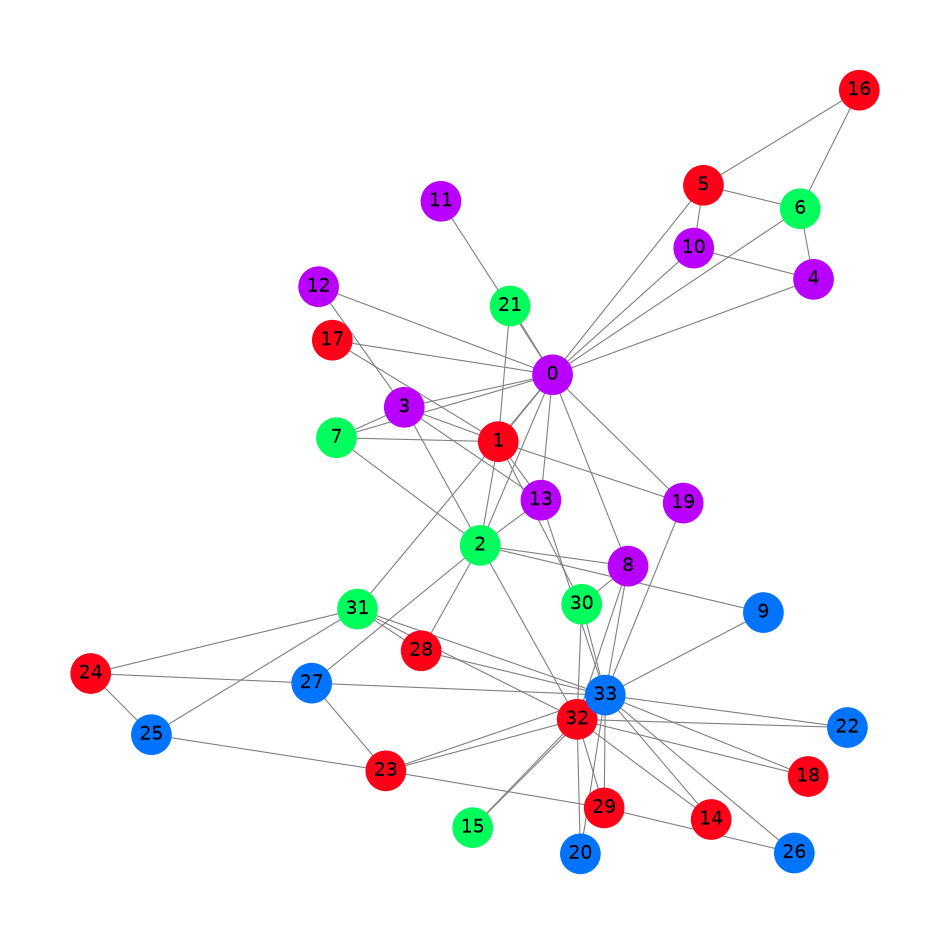

In [16]:
# Convert PyTorch Geometric data into a NetworkX graph
G = to_networkx(data, to_undirected=True)

# Calculate node positions
pos = nx.spring_layout(G, seed=0)

# Plot the graph
plt.figure(figsize=(12, 12))
plt.axis('off')

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_size=800,
    node_color=data.y,
    cmap="hsv",
    vmin=-2,
    vmax=3,
    width=0.8,
    edge_color="grey",
    font_size=14
)

plt.show()

## Visualizing a Graph: Node Positions and Labels

We can use NetworkX to visualize a graph stored in a PyTorch Geometric `Data` object.


### 1. Converting the graph

```python
G = to_networkx(data, to_undirected=True)
```

The function `to_networkx()` converts the graph from PyTorch Geometric's `Data` format into a NetworkX graph.

The argument `to_undirected=True` tells NetworkX to represent connections as undirected edges.

For example, if `edge_index` contains both \(0\to1\) and \(1\to0\), these represent the same undirected connection in the resulting graph.

### 2. Calculating node positions

```python
pos = nx.spring_layout(G, seed=0)
```

NetworkX needs a position for each node to draw the graph in two dimensions.

The spring layout uses a **force-directed algorithm**:

- Connected nodes are encouraged to remain close together.
- Nodes repel one another.
- The algorithm finds a visually useful arrangement by balancing these forces.

The parameter `seed=0` makes the layout reproducible under the same conditions.

**Important:** This is a graph-layout algorithm, not a clustering algorithm. It calculates positions; it does not assign cluster labels.

### 3. Coloring the nodes

```python
node_color=data.y
cmap="hsv"
vmin=-2
vmax=3
```

The argument `node_color=data.y` supplies the numerical labels used to color the nodes.

For example, suppose

```python
data.y = tensor([0, 1, 0, 2, 1])
```

Then:

- Nodes 0 and 2 have label 0 and receive the same color.
- Nodes 1 and 4 have label 1 and receive the same color.
- Node 3 has label 2 and receives the color corresponding to that label.

The color map `hsv` converts numerical values into colors. The values `vmin` and `vmax` specify the color-mapping range.

These labels might represent known classes, such as different categories of nodes. Coloring by labels is different from running a clustering algorithm.

### 4. A simple example

Consider a graph with five nodes and the following edges:

$$
E=\{(0,1),(1,2),(2,0),(2,3),(3,4)\}.
$$

The graph has two densely connected groups of nodes linked by a connection to node 3:

```text
       0
      / \
     1---2---3---4
```

We can create and visualize this graph independently of the Karate Club dataset.

```python
import networkx as nx
import matplotlib.pyplot as plt

# Define a graph
G = nx.Graph()

# Add edges
G.add_edges_from([
    (0, 1),
    (1, 2),
    (2, 0),
    (2, 3),
    (3, 4)
])

# Assign a label to each node
labels = {
    0: 0,
    1: 0,
    2: 0,
    3: 1,
    4: 1
}

# Calculate node positions
pos = nx.spring_layout(G, seed=0)

# Supply colors in node order
node_colors = [labels[node] for node in G.nodes()]

# Draw the graph
plt.figure(figsize=(7, 5))
plt.axis("off")

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_color=node_colors,
    cmap="coolwarm",
    node_size=1000,
    edge_color="grey"
)

plt.show()
```

Here, nodes 0, 1, and 2 share one label, while nodes 3 and 4 share another.

The visualization uses the graph structure to determine node positions and the labels to determine node colors. It does not discover those two groups automatically.

### 5. Interpreting the visualization for GNNs

When inspecting a graph, ask two separate questions:

1. **Structural question:** Which nodes are connected, and how is the graph organized?
2. **Label question:** Do nodes with the same label tend to occupy nearby regions in the visualization?

If nodes with the same label appear together, this may suggest that the labels are related to the graph structure. However, the spring layout is only a two-dimensional visualization, so visual proximity does not prove that nodes are similar or belong to the same cluster.

Also, if `data.y` contains ground-truth labels, coloring by those labels uses information supplied by the dataset. A GNN does not automatically know these labels when making predictions on unseen data.

**Key takeaway:** `spring_layout()` determines *where nodes are drawn*, while `node_color=data.y` determines *how nodes are colored*. These are two separate operations.

## 4. Train-Test Split

### Objective

We are studying **four-class node classification** on the Karate Club graph using a fixed neighborhood-aggregation baseline and, later, a Graph Convolutional Network (GCN).

The dataset contains only 34 nodes. Consequently, a conventional train-validation-test split would leave very few nodes in each subset. We will therefore use a **train-test split only**, reserving a portion of the labeled nodes for final evaluation.

### 4.1. Inspect the labels and existing training mask

Before choosing the split, we should inspect the dataset rather than assume a particular distribution of classes.

We will examine:

- `data.y`: the class label associated with each node.
- `data.train_mask`: the training mask supplied by PyTorch Geometric.
- The number of nodes belonging to each class.
- The number of nodes currently marked for training.

The built-in `KarateClub` dataset provides one training node per class by default. We will inspect this mask but will not automatically treat it as our final train-test split.

### 4.2. Construct a train-test split

We will create disjoint sets of training and test nodes:

$$
V = V_{\mathrm{train}} \sqcup V_{\mathrm{test}}.
$$

The split should be **stratified by class**, as far as the small class counts permit, so that both subsets contain representative examples of the four classes.

We will use the training-node labels to calculate the loss and fit the model. The test-node labels will be withheld from training and used only for the final evaluation.

Since the graph is very small, the resulting test accuracy will be sensitive to the particular split. We will interpret it as an illustrative result rather than a reliable estimate of performance on a broader population.

### 4.3. Transductive node classification

This experiment follows the **transductive learning** setting. We retain the complete graph, including its nodes and edges, during training and evaluation. The model can therefore use graph connectivity and node features when computing neighborhood representations.

However, only training-node labels contribute to the training loss. Test labels must not influence parameter updates or model selection.

We will use the same train-test split for both the fixed neighborhood-aggregation baseline and the GCN, allowing a fair comparison between them.

### 4.4. Permutation equivariance is a separate experiment

We will test permutation equivariance on the **entire graph**, independently of the train-test evaluation.

For a permutation matrix \(P\), consistently relabel the graph and its node features:

$$
A' = PAP^\top,
\qquad
X' = PX.
$$

A permutation-equivariant node classifier should satisfy

$$
f(PAP^\top,PX)=P f(A,X).
$$

We will compare the predictions before and after relabeling, mapping them back to the same node ordering. This test checks whether the implementation respects the graph's relabeling symmetry; it does not measure generalization accuracy.

### Summary

Our experimental design separates two questions:

1. **Classification:** How well do the fixed neighborhood-aggregation baseline and GCN predict node labels on the chosen train-test split?
2. **Symmetry:** Do the models' predictions transform consistently under arbitrary permutations of the entire graph's node labels?

We will first inspect the class distribution and existing training mask, then construct the train-test split. This ensures that our experimental choices are informed by the actual dataset rather than by an arbitrary splitting convention.

### 4.1: Inspect the labels

In [17]:
# Node labels
print("Labels:")
print(data.y)

print("\nShape:", data.y.shape)

# Unique classes and number of nodes in each class
classes, counts = torch.unique(data.y, return_counts=True)

print("\nClass distribution:")
for cls, count in zip(classes, counts):
    print(f"Class {cls.item()}: {count.item()} nodes")

Labels:
tensor([2, 3, 0, 2, 2, 3, 0, 0, 2, 1, 2, 2, 2, 2, 3, 0, 3, 3, 3, 2, 1, 0, 1, 3,
        3, 1, 1, 1, 3, 3, 0, 0, 3, 1])

Shape: torch.Size([34])

Class distribution:
Class 0: 7 nodes
Class 1: 7 nodes
Class 2: 9 nodes
Class 3: 11 nodes


### 4.2: Inspect PyG's existing training mask

In [18]:
print("Training mask:")
print(data.train_mask)

print("\nShape:", data.train_mask.shape)
print("Number of training nodes:", data.train_mask.sum().item())

Training mask:
tensor([ True, False, False, False,  True, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False,  True, False, False, False, False, False,
        False, False, False, False])

Shape: torch.Size([34])
Number of training nodes: 4


In [19]:
# Let's see which nodes PyG selected
train_nodes = data.train_mask.nonzero(as_tuple=True)[0]

print("Training nodes:", train_nodes)
print("Their labels:", data.y[train_nodes])

Training nodes: tensor([ 0,  4,  8, 24])
Their labels: tensor([2, 2, 2, 3])


### 4.3: Inspect the labels more concretely
For such a tiny graph, it maybe useful to see every node and its class.

In [20]:
for node, label in enumerate(data.y):
    print(f"Node {node:2d} -> Class {label.item()}")

Node  0 -> Class 2
Node  1 -> Class 3
Node  2 -> Class 0
Node  3 -> Class 2
Node  4 -> Class 2
Node  5 -> Class 3
Node  6 -> Class 0
Node  7 -> Class 0
Node  8 -> Class 2
Node  9 -> Class 1
Node 10 -> Class 2
Node 11 -> Class 2
Node 12 -> Class 2
Node 13 -> Class 2
Node 14 -> Class 3
Node 15 -> Class 0
Node 16 -> Class 3
Node 17 -> Class 3
Node 18 -> Class 3
Node 19 -> Class 2
Node 20 -> Class 1
Node 21 -> Class 0
Node 22 -> Class 1
Node 23 -> Class 3
Node 24 -> Class 3
Node 25 -> Class 1
Node 26 -> Class 1
Node 27 -> Class 1
Node 28 -> Class 3
Node 29 -> Class 3
Node 30 -> Class 0
Node 31 -> Class 0
Node 32 -> Class 3
Node 33 -> Class 1


### 4.4: Construct the split

In [21]:
from sklearn.model_selection import train_test_split
import torch

seed = 42

# Scikit-learn performs the split on CPU-compatible arrays.
node_indices = torch.arange(data.num_nodes).cpu().numpy()
labels = data.y.cpu().numpy()

train_idx, test_idx = train_test_split(
    node_indices,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

# Create masks on the same device as the labels.
device = data.y.device

data.train_mask = torch.zeros(
    data.num_nodes, dtype=torch.bool, device=device
)
data.test_mask = torch.zeros(
    data.num_nodes, dtype=torch.bool, device=device
)

data.train_mask[torch.as_tensor(train_idx, device=device)] = True
data.test_mask[torch.as_tensor(test_idx, device=device)] = True

### 4.5: Verify the split

In [22]:
for name, mask in [
    ("Train", data.train_mask),
    ("Test", data.test_mask),
]:
    classes, counts = torch.unique(
        data.y[mask], return_counts=True
    )

    print(f"\n{name} class distribution:")
    for cls, count in zip(classes, counts):
        print(f"  Class {cls.item()}: {count.item()} nodes")

# Confirm that the masks are disjoint and cover all nodes.
assert not torch.any(data.train_mask & data.test_mask)
assert torch.all(data.train_mask | data.test_mask)

print("\nSplit verification passed.")


Train class distribution:
  Class 0: 5 nodes
  Class 1: 5 nodes
  Class 2: 6 nodes
  Class 3: 7 nodes

Test class distribution:
  Class 0: 2 nodes
  Class 1: 2 nodes
  Class 2: 3 nodes
  Class 3: 4 nodes

Split verification passed.


## 5. Baseline Model: Fixed Neighborhood Aggregation

We'll build a simpler model that uses the graph but does not learn its neighborhood-aggregation rule.

The idea is to aggregate each node's features with those of its neighbors, then train a linear classifier on the aggregated representations.

**Why did we choose this baseline?**
Our goal is to compare two approaches to node classification:
- Fixed neighborhood aggregation: use the graph to combine neighboring node features, then learn a simple linear classifier.
- GCN (later): learn graph-based representations using trainable transformations and normalized neighborhood aggregation across multiple layers.

The baseline answers a specific question:

>How well can we classify nodes using graph structure and a simple, fixed aggregation rule, without learning a sophisticated graph representation?

It gives us a reference point for evaluating whether the additional complexity of a GCN is useful.

**What exactly does the baseline do?**

Suppose node $i$ has feature vector $x_i$, and its neighbors are $N(i)$. Our baseline computes
$$
h_i=\frac{1}{|N(i)|+1}
\left(x_i+\sum_{j\in N(i)}x_j\right).
$$

It then predicts the class using
$$
z_i=Wh_i+b,
$$

where $W$ and $b$ are learned from the training labels

So the model has following stages:

- Input node features \(X\): one feature vector per node.

- Fixed neighborhood aggregation: combine each node with its neighbors

- Trainable linear classifier: map aggregated features to four class logits

The aggregation stage is fixed; the classifier is trainable.

This is a useful baseline because it separates two sources of information: the graph structure determines which features are combined, while the classifier learns how to use the resulting representation.

It is not a universal lower bound on GNN performance. A GCN can perform worse on a small dataset, particularly with only 24 training nodes.

### 5.1. Mathematical formulation

Let $A$ be the adjacency matrix and $X\in\mathbb{R}^{N\times d}$ the node-feature matrix. Add self-loops:
$$
\widetilde A=A+I,
\qquad
\widetilde D_{ii}=\sum_j\widetilde A_{ij}.
$$

Compute the mean of each node's own features and its neighbors' features:
$$
H=\widetilde D^{-1}\widetilde A X.
$$

Then classify the aggregated features:
$$
\boxed{Z=HW+b}
$$

where $W$ and $b$ are the trainable parameters, and $Z\in\mathbb{R}^{N\times 4}$ contains the four class logits for each node.

The aggregation is fixed; only the classifier is learned.

**Why self-loops?**

Recall that the adjacency matrix $A$ records edges between different nodes. Its diagonal is zero if the graph has no self-loops.

When we compute
$$
H=\widetilde D^{-1}\widetilde A X,
\qquad \widetilde A=A+I,
$$

we add a self-loop to every node.

The purpose is simple: each node should aggregate its own features as well as its neighbors' features.

Without self-loops, the aggregation would be
$$
h_i=\frac{1}{|N(i)|}\sum_{j\in N(i)}x_j.
$$

With self-loops, it becomes
$$
h_i=\frac{x_i+\sum_{j\in N(i)}x_j}{|N(i)|+1}.
$$

Compare the two cases:

- Only neighbors contribute (no self-loops): node $i$ receives information from its neighbors but excludes its own feature vector. A node with no neighbors would also have a zero aggregate under this formula.

- The node contributes to itself (with self-loops): the self-loop lets node $i$'s own features participate in the average, alongside the features of its neighbors.

**Why is that important for our dataset?**

PyG's Karate Club dataset uses one-hot node-identity features by default. Thus, each node starts with a feature vector identifying that node.

When we aggregate neighbors' features, we collect information about which nodes are connected to it. Adding a self-loop also retains information about the node itself.

Without the self-loop, the baseline's representation would be constructed entirely from neighboring nodes' identity features. With the self-loop, it includes the node's own identity feature too.

**Does adding a self-loop mean the model is learning from itself?**

Not quite. The self-loop is not an extra trainable parameter. We add the identity matrix $I$ to the adjacency matrix, which assigns each node a weight of one for its own feature vector before normalization.

The normalization then determines how much weight the node and its neighbors receive. In our mean-aggregation baseline, each receives equal weight.

For example, if node $i$ has three neighbors, then
$$
h_i=\frac14(x_i+x_{j_1}+x_{j_2}+x_{j_3}).
$$

The node's own feature vector receives weight $1/4$, just like each neighbor's feature vector.

A GCN uses a closely related construction, although the original GCN commonly uses symmetric degree normalization:
$$
H^{(l+1)}
=\sigma\!\left(
\widetilde D^{-1/2}\widetilde A
\widetilde D^{-1/2}H^{(l)}W^{(l)}
\right).
$$

Our baseline instead uses row normalization, $\widetilde D^{-1}\widetilde A$, to compute a simple neighbor average. The two normalizations are related, but they are not identical.

**One limitation to understand.**

Because the default features are one-hot node identities, the baseline may learn patterns specific to these 34 nodes. It does not automatically learn a transferable representation of nationality or community membership.

Our goal here is narrower: establish a transparent graph-aware reference model, compare it fairly with a GCN, and test the permutation-equivariance property.

Under a consistent permutation of the adjacency matrix and feature matrix, both this fixed aggregation operation and the shared linear classifier should transform their node-level outputs in the same way. That gives us a mathematically motivated baseline for the symmetry experiment too.

In short: we chose this model because it uses graph structure without introducing learned graph convolutions, and we added self-loops so that each node's own features are included in its neighborhood representation.

### 5.2: Implement the baseline
We'll use PyTorch directly first, without PyG's GNN layers. This makes the mathematical operations explicit.

In [23]:
import torch.nn as nn
import torch.nn.functional as F

# Use the graph's current device.
device = data.x.device

# Move the graph data and masks to the same device if necessary.
data = data.to(device)

# Construct the adjacency matrix.
num_nodes = data.num_nodes
A = torch.zeros(
    (num_nodes, num_nodes),
    dtype=data.x.dtype,
    device=device
)

# Karate Club is undirected: record both directions.
src, dst = data.edge_index
A[src, dst] = 1.0
A[dst, src] = 1.0

# Add self-loops.
A_tilde = A + torch.eye(
    num_nodes, dtype=A.dtype, device=device
)

# Compute row-normalized adjacency.
degree = A_tilde.sum(dim=1)
A_norm = A_tilde / degree.unsqueeze(1)

# Fixed neighborhood aggregation.
H = A_norm @ data.x

print("Node feature shape:", data.x.shape)
print("Aggregated feature shape:", H.shape)
print("Normalized adjacency shape:", A_norm.shape)

Node feature shape: torch.Size([34, 34])
Aggregated feature shape: torch.Size([34, 34])
Normalized adjacency shape: torch.Size([34, 34])


**What this demonstrates?**

Every node receives the average of its own feature vector and those of its neighbors. We compute the aggregation once because it has no trainable parameters.

### 5.3: Define the classifier

In [24]:
class NeighborhoodBaseline(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.linear = nn.Linear(in_channels, num_classes)

    def forward(self, H):
        return self.linear(H)


model = NeighborhoodBaseline(
    in_channels=H.size(1),
    num_classes=4
).to(device)

print(model)

NeighborhoodBaseline(
  (linear): Linear(in_features=34, out_features=4, bias=True)
)


### 5.4: Train using only the training nodes

In [25]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
num_epochs = 300

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(H)

    # Only training-node labels contribute to the loss.
    loss = F.cross_entropy(
        logits[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch + 1:3d} | Loss: {loss.item():.4f}")

Epoch  25 | Loss: 1.2007
Epoch  50 | Loss: 1.0333
Epoch  75 | Loss: 0.9000
Epoch 100 | Loss: 0.7927
Epoch 125 | Loss: 0.7053
Epoch 150 | Loss: 0.6331
Epoch 175 | Loss: 0.5725
Epoch 200 | Loss: 0.5210
Epoch 225 | Loss: 0.4767
Epoch 250 | Loss: 0.4383
Epoch 275 | Loss: 0.4047
Epoch 300 | Loss: 0.3751


### 5.5: Evaluate on test nodes

In [26]:
model.eval()

with torch.no_grad():
    logits = model(H)
    predictions = logits.argmax(dim=1)

test_correct = (
    predictions[data.test_mask] == data.y[data.test_mask]
).sum()

test_total = data.test_mask.sum()

test_accuracy = test_correct.float() / test_total

print(f"Test accuracy: {test_accuracy.item():.4f}")
print(f"Correct: {test_correct.item()} / {test_total.item()}")

Test accuracy: 0.1818
Correct: 2 / 11


### 5.6: Diagnostic - using test as cv

#### 5.6.1: Modified training loop

In [27]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
num_epochs = 300

train_losses = []
train_accuracies = []
test_accuracies = []  # Diagnostic only; do not select epochs from this.

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(H)

    loss = F.cross_entropy(
        logits[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    # Record metrics after the parameter update.
    model.eval()
    with torch.no_grad():
        logits = model(H)
        predictions = logits.argmax(dim=1)

        train_acc = (
            predictions[data.train_mask] == data.y[data.train_mask]
        ).float().mean().item()

        test_acc = (
            predictions[data.test_mask] == data.y[data.test_mask]
        ).float().mean().item()

    train_losses.append(loss.item())
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"Train acc: {train_acc:.2%} | "
            f"Test acc: {test_acc:.2%}"
        )

Epoch  25 | Loss: 0.3286 | Train acc: 100.00% | Test acc: 18.18%
Epoch  50 | Loss: 0.2906 | Train acc: 100.00% | Test acc: 18.18%
Epoch  75 | Loss: 0.2599 | Train acc: 100.00% | Test acc: 18.18%
Epoch 100 | Loss: 0.2347 | Train acc: 100.00% | Test acc: 18.18%
Epoch 125 | Loss: 0.2135 | Train acc: 100.00% | Test acc: 18.18%
Epoch 150 | Loss: 0.1955 | Train acc: 100.00% | Test acc: 18.18%
Epoch 175 | Loss: 0.1798 | Train acc: 100.00% | Test acc: 18.18%
Epoch 200 | Loss: 0.1662 | Train acc: 100.00% | Test acc: 18.18%
Epoch 225 | Loss: 0.1541 | Train acc: 100.00% | Test acc: 18.18%
Epoch 250 | Loss: 0.1435 | Train acc: 100.00% | Test acc: 18.18%
Epoch 275 | Loss: 0.1339 | Train acc: 100.00% | Test acc: 18.18%
Epoch 300 | Loss: 0.1254 | Train acc: 100.00% | Test acc: 18.18%


### 5.6.2: Plot the learning curve

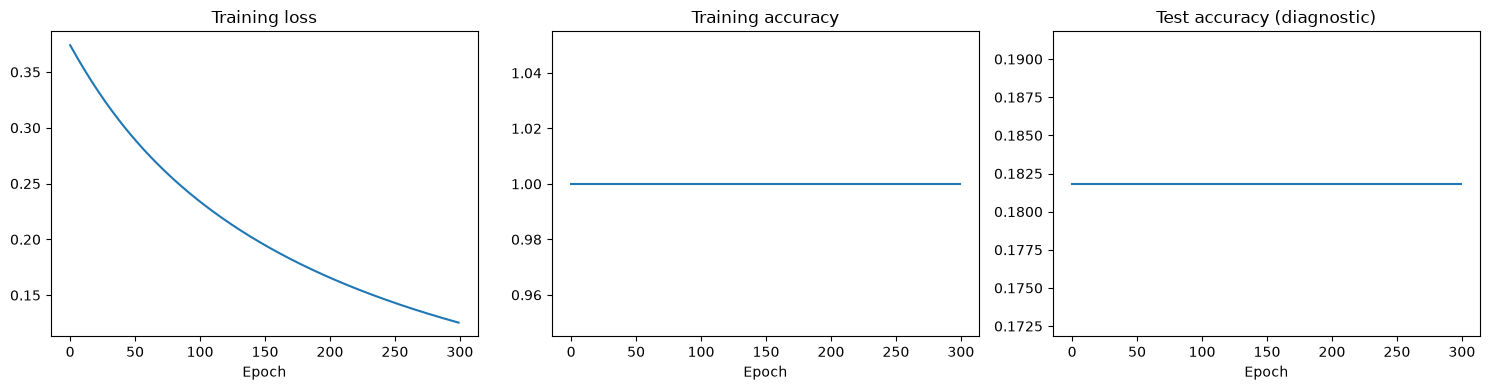

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(train_losses)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")

axes[1].plot(train_accuracies)
axes[1].set_title("Training accuracy")
axes[1].set_xlabel("Epoch")

axes[2].plot(test_accuracies)
axes[2].set_title("Test accuracy (diagnostic)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

### 5.7: Conclusion

#### Future Experiment: Learning on Subgraphs and Graph Minors

The current experiment performs transductive node classification on the complete Karate Club graph. Although the model uses neighborhood aggregation, its test accuracy remains low while its training accuracy reaches 100%.

This motivates investigating how the choice of graph domain affects learning. Rather than always training and evaluating on the entire graph, we will explore experiments involving subgraphs and, separately, graph minors.

#### Experiment A: Subgraph-based learning

A subgraph is obtained by selecting a subset of the original nodes and retaining some or all of the edges between them. We will investigate how restricting the graph changes the information available to a message-passing model.

Possible experiments include:

- **Induced subgraphs:** Select a subset of nodes and retain every original edge between selected nodes.
- **Neighborhood subgraphs:** Select target nodes together with their \(k\)-hop neighborhoods.
- **Connected subgraphs:** Restrict the experiment to connected regions of the original graph.
- **Subgraph-based evaluation:** Compare predictions on selected regions with predictions obtained from the full graph.

We will examine how the number of nodes, connectivity, class distribution, and neighborhood structure affect classification performance.

#### Experiment B: Graph minors

A graph minor is obtained through operations such as vertex deletion, edge deletion, and edge contraction. Unlike arbitrary subgraph selection, edge contraction can identify multiple vertices as a single vertex.

We will investigate whether graph simplification through carefully chosen minor operations preserves useful community structure or removes information needed for classification.

Because contraction changes the relationship between vertices and labels, we will define an explicit rule for assigning labels and features to contracted vertices before training a model.

#### Experimental controls

To make comparisons meaningful, we will:

1. Define the graph transformation before evaluating its effect.
2. Record the resulting graph's size, connectivity, and class distribution.
3. Specify how node features and labels are transferred to the transformed graph.
4. Compare models under clearly defined and consistent evaluation protocols.
5. Test permutation equivariance separately on each transformed graph where appropriate.

#### Research question

**How does changing the graph domain through subgraph selection or graph simplification affect the information available for node classification and the behaviour of graph neural networks?**

This experiment will help distinguish the effects of neighborhood structure, graph size, and graph transformations on learning.

## 6. Experiment with PyG Training Mask

### 6.1: Load the dataset fresh

In [29]:
dataset = KarateClub()
data = dataset[0]

print("Original training nodes:", data.train_mask.sum().item())

Original training nodes: 4


### 6.2: Use PyG mask to create train-test split

In [30]:
# Original PyG training mask: 4 labeled nodes
train_mask = data.train_mask.clone()

# Nodes not used for training
remaining_nodes = (~train_mask).nonzero(as_tuple=True)[0]

# Reproducible random selection
generator = torch.Generator().manual_seed(42)
permutation = torch.randperm(
    len(remaining_nodes),
    generator=generator
)

# Select 4 validation nodes
val_nodes = remaining_nodes[permutation[:4]]

# Remaining nodes become the test set
test_nodes = remaining_nodes[permutation[4:]]

# Create Boolean masks
val_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)

val_mask[val_nodes] = True
test_mask[test_nodes] = True

# Attach the masks to the data object
data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

print("Train:", data.train_mask.sum().item())
print("Validation:", data.val_mask.sum().item())
print("Test:", data.test_mask.sum().item())

Train: 4
Validation: 4
Test: 26


### 6.3: Train the model

In [31]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
num_epochs = 300

train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    # Training phase
    model.train()
    optimizer.zero_grad()

    logits = model(H)

    loss = F.cross_entropy(
        logits[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    # Evaluation phase
    model.eval()
    with torch.no_grad():
        logits = model(H)
        predictions = logits.argmax(dim=1)

        train_acc = (
            predictions[data.train_mask] == data.y[data.train_mask]
        ).float().mean().item()

        val_acc = (
            predictions[data.val_mask] == data.y[data.val_mask]
        ).float().mean().item()

    train_losses.append(loss.item())
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"Train acc: {train_acc:.2%} | "
            f"Val acc: {val_acc:.2%}"
        )

Epoch  25 | Loss: 3.8470 | Train acc: 25.00% | Val acc: 25.00%
Epoch  50 | Loss: 3.3719 | Train acc: 25.00% | Val acc: 25.00%
Epoch  75 | Loss: 2.9166 | Train acc: 25.00% | Val acc: 25.00%
Epoch 100 | Loss: 2.4952 | Train acc: 25.00% | Val acc: 25.00%
Epoch 125 | Loss: 2.1267 | Train acc: 25.00% | Val acc: 25.00%
Epoch 150 | Loss: 1.8203 | Train acc: 25.00% | Val acc: 25.00%
Epoch 175 | Loss: 1.5646 | Train acc: 50.00% | Val acc: 50.00%
Epoch 200 | Loss: 1.3396 | Train acc: 50.00% | Val acc: 50.00%
Epoch 225 | Loss: 1.1333 | Train acc: 50.00% | Val acc: 50.00%
Epoch 250 | Loss: 0.9440 | Train acc: 50.00% | Val acc: 50.00%
Epoch 275 | Loss: 0.7752 | Train acc: 50.00% | Val acc: 50.00%
Epoch 300 | Loss: 0.6314 | Train acc: 75.00% | Val acc: 50.00%


### 6.4: Train on test and val set

In [32]:
final_train_mask = data.train_mask | data.val_mask

print(final_train_mask.sum().item())  # 8

8


In [33]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
selected_num_epochs = 300
for epoch in range(selected_num_epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(H)

    loss = F.cross_entropy(
        logits[final_train_mask],
        data.y[final_train_mask]
    )

    loss.backward()
    optimizer.step()

### 6.5: Final Prediction

In [34]:
model.eval()

with torch.no_grad():
    logits = model(H)
    predictions = logits.argmax(dim=1)

test_correct = (
    predictions[data.test_mask] == data.y[data.test_mask]
).sum()

test_total = data.test_mask.sum()

test_accuracy = test_correct.float() / test_total

print(f"Test accuracy: {test_accuracy.item():.4f}")
print(f"Correct: {test_correct.item()} / {test_total.item()}")

Test accuracy: 0.5769
Correct: 15 / 26


## 7. GNN Model: Graph Convolution Network

### 7.1: Verify the masks

In [35]:
print("Train:", data.train_mask.sum().item())
print("Validation:", data.val_mask.sum().item())
print("Test:", data.test_mask.sum().item())

assert data.train_mask.sum().item() == 4
assert data.val_mask.sum().item() == 4
assert data.test_mask.sum().item() == 26

Train: 4
Validation: 4
Test: 26


### 7.2: Define the GNN model

In [36]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)

        return x


In [37]:
model = GCN(
    in_channels=data.num_node_features,
    hidden_channels=16,
    out_channels=dataset.num_classes
)

print(model)

GCN(
  (conv1): GCNConv(34, 16)
  (conv2): GCNConv(16, 4)
)


### 7.3: Train using the same mask

In [38]:
ooptimizer = torch.optim.Adam(model.parameters(), lr=0.01)
num_epochs = 300

train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(data)

    loss = F.cross_entropy(
        logits[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        logits = model(data)
        predictions = logits.argmax(dim=1)

        train_acc = (
            predictions[data.train_mask] == data.y[data.train_mask]
        ).float().mean().item()

        val_acc = (
            predictions[data.val_mask] == data.y[data.val_mask]
        ).float().mean().item()

    train_losses.append(loss.item())
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"Train acc: {train_acc:.2%} | "
            f"Val acc: {val_acc:.2%}"
        )

Epoch  25 | Loss: 1.3994 | Train acc: 50.00% | Val acc: 25.00%
Epoch  50 | Loss: 1.3903 | Train acc: 50.00% | Val acc: 25.00%
Epoch  75 | Loss: 1.3774 | Train acc: 50.00% | Val acc: 25.00%
Epoch 100 | Loss: 1.3743 | Train acc: 50.00% | Val acc: 25.00%
Epoch 125 | Loss: 1.3725 | Train acc: 50.00% | Val acc: 25.00%
Epoch 150 | Loss: 1.4195 | Train acc: 50.00% | Val acc: 25.00%
Epoch 175 | Loss: 1.3582 | Train acc: 50.00% | Val acc: 25.00%
Epoch 200 | Loss: 1.3820 | Train acc: 50.00% | Val acc: 25.00%
Epoch 225 | Loss: 1.3871 | Train acc: 50.00% | Val acc: 25.00%
Epoch 250 | Loss: 1.4033 | Train acc: 50.00% | Val acc: 25.00%
Epoch 275 | Loss: 1.3603 | Train acc: 50.00% | Val acc: 25.00%
Epoch 300 | Loss: 1.3523 | Train acc: 50.00% | Val acc: 25.00%


### 7.4: Train on test and val set

In [39]:
final_train_mask = data.train_mask | data.val_mask

print(final_train_mask.sum().item())  # 8

8


In [40]:
omodel = GCN(
    in_channels=data.num_node_features,
    hidden_channels=16,
    out_channels=dataset.num_classes
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

selected_num_epochs = 200  # Example; use your selected epoch count

for epoch in range(selected_num_epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(data)

    loss = F.cross_entropy(
        logits[final_train_mask],
        data.y[final_train_mask]
    )

    loss.backward()
    optimizer.step()

### 7.5: Evaluate on test set

In [41]:
model.eval()

with torch.no_grad():
    logits = model(data)
    predictions = logits.argmax(dim=1)

    test_acc = (
        predictions[data.test_mask] == data.y[data.test_mask]
    ).float().mean().item()

print(f"Final test accuracy: {test_acc:.2%}")

Final test accuracy: 92.31%


### 7.6: One Conv and one linear layer

In [42]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.out = Linear(hidden_channels, out_channels, bias=True)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.out(x)

        return x

In [43]:
model_lin = GCN(
    in_channels=data.num_node_features,
    hidden_channels=16,
    out_channels=dataset.num_classes
)

print(model_lin)

GCN(
  (conv1): GCNConv(34, 16)
  (out): Linear(in_features=16, out_features=4, bias=True)
)


In [44]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
num_epochs = 300

train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    model_lin.train()
    optimizer.zero_grad()

    logits = model_lin(data)

    loss = F.cross_entropy(
        logits[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    model_lin.eval()
    with torch.no_grad():
        logits = model_lin(data)
        predictions = logits.argmax(dim=1)

        train_acc = (
            predictions[data.train_mask] == data.y[data.train_mask]
        ).float().mean().item()

        val_acc = (
            predictions[data.val_mask] == data.y[data.val_mask]
        ).float().mean().item()

    train_losses.append(loss.item())
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"Train acc: {train_acc:.2%} | "
            f"Val acc: {val_acc:.2%}"
        )

Epoch  25 | Loss: 1.4149 | Train acc: 25.00% | Val acc: 0.00%
Epoch  50 | Loss: 1.3936 | Train acc: 25.00% | Val acc: 0.00%
Epoch  75 | Loss: 1.4091 | Train acc: 25.00% | Val acc: 0.00%
Epoch 100 | Loss: 1.3847 | Train acc: 25.00% | Val acc: 0.00%
Epoch 125 | Loss: 1.3900 | Train acc: 25.00% | Val acc: 0.00%
Epoch 150 | Loss: 1.4042 | Train acc: 25.00% | Val acc: 0.00%
Epoch 175 | Loss: 1.3881 | Train acc: 25.00% | Val acc: 0.00%
Epoch 200 | Loss: 1.3814 | Train acc: 25.00% | Val acc: 0.00%
Epoch 225 | Loss: 1.4218 | Train acc: 25.00% | Val acc: 0.00%
Epoch 250 | Loss: 1.3947 | Train acc: 25.00% | Val acc: 0.00%
Epoch 275 | Loss: 1.4228 | Train acc: 25.00% | Val acc: 0.00%
Epoch 300 | Loss: 1.4157 | Train acc: 25.00% | Val acc: 0.00%


In [45]:
omodel = GCN(
    in_channels=data.num_node_features,
    hidden_channels=16,
    out_channels=dataset.num_classes
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

selected_num_epochs = 200  # Example; use your selected epoch count

for epoch in range(selected_num_epochs):
    model_lin.train()
    optimizer.zero_grad()

    logits = model(data)

    loss = F.cross_entropy(
        logits[final_train_mask],
        data.y[final_train_mask]
    )

    loss.backward()
    optimizer.step()

In [46]:
model_lin.eval()

with torch.no_grad():
    logits = model(data)
    predictions = logits.argmax(dim=1)

    test_acc = (
        predictions[data.test_mask] == data.y[data.test_mask]
    ).float().mean().item()

print(f"Final test accuracy: {test_acc:.2%}")

Final test accuracy: 92.31%


**Observation:** So, we see that GCN is performing much better than our baseline model.